# 11 — Attribution Features: Which Race, Not Whether

Notebook 10 left the project with a lopsided result. **Detection is close to
solved** on this benchmark: a 400 N diagnostic window catches 97 % of
real-damage recordings at 8.3 % false alarms on an unseen healthy bearing.
**Attribution is not**: the race is called correctly for 81.8 % of bearings,
and two — KA15 and KA22 — are never called correctly at any operating point.

Notebook 10 also explained why. The energy that low load recovers sits at
**shaft rate**, which separates faulty from healthy but carries no information
about *which* race is damaged, so recovered windows scatter across both
classes. Every feature this project has used describes the *level* at a fault
frequency. None describes its **structure**.

Classical diagnostics says the structure is where the race lives. An
inner-race defect travels in and out of the load zone once per revolution, so
its ball-pass energy is amplitude-modulated at shaft rate and appears as
**sidebands at BPFI ± k·fr**. An outer-race defect sits still relative to the
load zone and is modulated far less. This notebook builds those features and
asks whether they do the job.

The answer arrives in two stages, and the first framing turns out to be wrong.

In [1]:
import pathlib, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import loadmat
from scipy.signal import butter, sosfiltfilt, hilbert, get_window
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import LeaveOneGroupOut, cross_val_score

DATA_DIR = pathlib.Path("../data/raw/paderborn")
OUT = pathlib.Path("../data/processed")
HI, LO = "N15_M07_F10", "N15_M07_F04"
TAG = {HI: "1000 N", LO: "400 N"}
FS, N_KEEP = 64_000, 245_760
# 1.024 s windows -> 0.977 Hz bins. Notebooks 07-10 used 16 384 (3.9 Hz), which cannot
# separate BPFI + fr (148 Hz) from 2 x BPFO (153 Hz). Sideband work needs the resolution;
# the cost is 3 averaged sub-windows per run instead of 15, so features are per-run.
WIN = 65_536
N_SUB = N_KEEP // WIN
HANN = get_window("hann", WIN)
F = np.fft.rfftfreq(WIN, 1 / FS)
FLOOR = (F > 10) & (F < 400)
SOS = butter(4, (1000, 20000), btype="bandpass", fs=FS, output="sos")
N_BALLS, BD, PD = 8, 6.75, 29.05
O_BPFO, O_BPFI = N_BALLS / 2 * (1 - BD / PD), N_BALLS / 2 * (1 + BD / PD)
HALF = 3.0                       # Hz half-width, ~3 bins

BEARINGS = ([(f"K00{i}", "Healthy", "healthy") for i in range(1, 7)]
            + [(c, "OR", "artificial") for c in ("KA01", "KA03", "KA05", "KA07")]
            + [(c, "IR", "artificial") for c in ("KI01", "KI03", "KI05", "KI07")]
            + [(c, "OR", "real") for c in ("KA04", "KA15", "KA16", "KA22", "KA30")]
            + [(c, "IR", "real") for c in ("KI04", "KI14", "KI16", "KI17", "KI18", "KI21")])


def channels(p):
    p = pathlib.Path(p)
    ch = loadmat(p)[p.stem]["Y"][0, 0][0]
    return {str(x["Name"][0]): x["Data"].squeeze() for x in ch}


def envelope_spectrum(cond, code, run):
    c = channels(DATA_DIR / code / f"{cond}_{code}_{run}.mat")
    v = c["vibration_1"][:N_KEEP].astype(np.float64)
    fr = float(c["speed"].mean()) / 60
    e = np.abs(hilbert(sosfiltfilt(SOS, v)))
    w = (e - e.mean())[: N_SUB * WIN].reshape(N_SUB, WIN)
    w = w - w.mean(axis=1, keepdims=True)
    return (np.abs(np.fft.rfft(w * HANN, axis=1)) ** 2).mean(axis=0), fr


def peak_db(spec, hz, floor):
    m = (F >= hz - HALF) & (F <= hz + HALF)
    return 10 * np.log10(spec[m].max() / floor)


def run_row(cond, code, run):
    spec, fr = envelope_spectrum(cond, code, run)
    fl = np.median(spec[FLOOR])
    bpfo, bpfi = O_BPFO * fr, O_BPFI * fr
    g = lambda hz: peak_db(spec, hz, fl)
    r = dict(fr_Hz=fr, BPFO=g(bpfo), BPFI=g(bpfi), FR=g(fr),
             BPFO_h2=g(2 * bpfo), BPFI_h2=g(2 * bpfi))
    r["BPFI_sb1"] = 0.5 * (g(bpfi - fr) + g(bpfi + fr))     # the textbook IR discriminator
    r["BPFI_sb2"] = 0.5 * (g(bpfi - 2 * fr) + g(bpfi + 2 * fr))
    r["BPFO_sb1"] = 0.5 * (g(bpfo - fr) + g(bpfo + fr))
    r["BPFI_h2_sb1"] = 0.5 * (g(2 * bpfi - fr) + g(2 * bpfi + fr))
    r["SBR_BPFI"] = r["BPFI_sb1"] - r["BPFI"]               # sideband-to-carrier ratios
    r["SBR_BPFO"] = r["BPFO_sb1"] - r["BPFO"]
    r["SBR_diff"] = r["SBR_BPFI"] - r["SBR_BPFO"]
    r["BPFI_minus_BPFO"] = r["BPFI"] - r["BPFO"]            # plain carrier contrast
    r["HARM_BPFO"] = r["BPFO_h2"] - r["BPFO"]
    r["HARM_BPFI"] = r["BPFI_h2"] - r["BPFI"]
    return r


def build(cond):
    path = OUT / f"pu_{cond}_sidebands.csv"
    if path.exists():
        return pd.read_csv(path)
    rows = []
    for code, cls, dom in BEARINGS:
        for run in range(1, 21):
            r = run_row(cond, code, run)
            r.update(Code=code, Condition=cls, Domain=dom, Run=run)
            rows.append(r)
    d = pd.DataFrame(rows)
    d.to_csv(path, index=False)
    return d


t0 = time.time()
S = {c: build(c) for c in (HI, LO)}
LABEL = S[HI].drop_duplicates("Code").set_index("Code")[["Condition", "Domain"]]
ART = sorted(LABEL.index[LABEL["Domain"] == "artificial"])
REAL = sorted(LABEL.index[LABEL["Domain"] == "real"])
RF_KW = dict(n_estimators=300, random_state=0, n_jobs=-1)

C_BLUE, C_ORANGE = "#2a78d6", "#eb6834"
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, BASE, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans"],
    "text.color": INK, "axes.titlecolor": INK, "axes.labelcolor": INK2,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.edgecolor": BASE,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "legend.frameon": False,
})
RACE_COLOR = {"OR": C_BLUE, "IR": C_ORANGE}
print(f"{S[HI].shape[0]} runs x {S[HI].shape[1]} cols per load  ({time.time() - t0:.0f}s)  "
      f"| bin width {F[1]:.3f} Hz, BPFI +- fr separated by {O_BPFI * 25 - (O_BPFI * 25 - 25):.0f} Hz")

500 runs x 20 cols per load  (0s)  | bin width 0.977 Hz, BPFI +- fr separated by 25 Hz


## The physics, seen directly

Before any modelling: look at the envelope spectrum around BPFI for a strong
inner-race bearing and a strong outer-race bearing. If the load-zone argument
is right, the inner-race case should show a picket fence at BPFI ± fr and the
outer-race case should not.

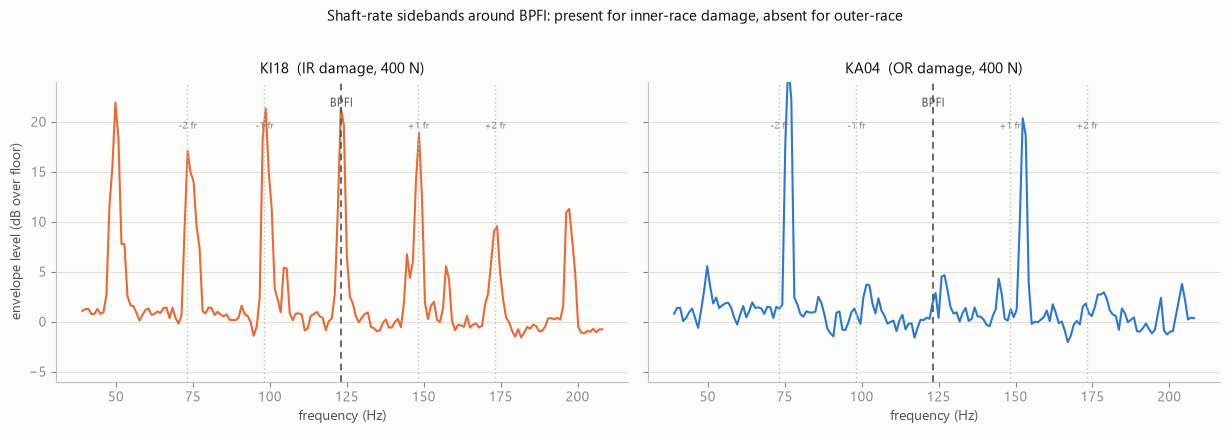

group medians at 400 N:
                       BPFO   BPFI  BPFI_sb1  BPFO_sb1  SBR_BPFI  SBR_BPFO  SBR_diff  BPFI_minus_BPFO
Domain     Condition                                                                                 
artificial IR          8.41   9.18     12.82     17.42      2.43      5.67     -3.83             1.38
           OR         15.20   3.24      6.72     12.98      2.44     -2.62      6.14           -11.77
healthy    Healthy     3.86   2.20     13.87     22.13     11.43     15.21     -6.28            -1.64
real       IR          9.87  11.08      8.42     10.38     -2.55      1.66     -3.93             1.57
           OR          8.38   4.81      5.35      9.30      0.55      1.25     -0.14            -3.04


In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12.4, 4.2), sharey=True)
for ax, (code_, race) in zip(axes, (("KI18", "IR"), ("KA04", "OR"))):
    spec, fr = envelope_spectrum(LO, code_, 1)
    for run in range(2, 21):
        s2, _ = envelope_spectrum(LO, code_, run)
        spec = spec + s2
    spec /= 20
    fl = np.median(spec[FLOOR])
    db = 10 * np.log10(spec / fl)
    bpfi = O_BPFI * fr
    m = (F >= bpfi - 3.4 * fr) & (F <= bpfi + 3.4 * fr)
    ax.plot(F[m], db[m], color=RACE_COLOR[race], lw=1.5)
    ax.axvline(bpfi, color=INK2, lw=1.2, ls=(0, (4, 3)))
    ax.text(bpfi, 21.5, "BPFI", color=INK2, fontsize=8.5, ha="center")
    for k in (-2, -1, 1, 2):
        ax.axvline(bpfi + k * fr, color=BASE, lw=1.0, ls=(0, (1, 2)))
        ax.text(bpfi + k * fr, 19.3, f"{k:+d} fr", color=MUTED, fontsize=7.5, ha="center")
    ax.set_xlabel("frequency (Hz)")
    ax.set_title(f"{code_}  ({race} damage, 400 N)", fontsize=10.5)
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("envelope level (dB over floor)")
axes[0].set_ylim(-6, 24)
fig.suptitle("Shaft-rate sidebands around BPFI: present for inner-race damage, absent for outer-race",
             fontsize=11, y=1.02)
plt.tight_layout()
plt.show()

cols = ["BPFO", "BPFI", "BPFI_sb1", "BPFO_sb1", "SBR_BPFI", "SBR_BPFO",
        "SBR_diff", "BPFI_minus_BPFO"]
print("group medians at 400 N:")
print(S[LO].groupby(["Domain", "Condition"])[cols].median().round(2).to_string())

## Do the candidate discriminators actually separate the races?

Two candidates, both level-invariant by construction (a dB difference is a
ratio):

- **`SBR_diff`** — how much stronger the BPFI sidebands are relative to their
  carrier than the BPFO sidebands are to theirs. This is the direct encoding of
  the load-zone argument.
- **`BPFI_minus_BPFO`** — the plain carrier contrast, i.e. "which fault
  frequency is louder". No structure at all; included as the thing to beat.

Scored as a separation between the OR and IR damaged bearings, at bearing
level.

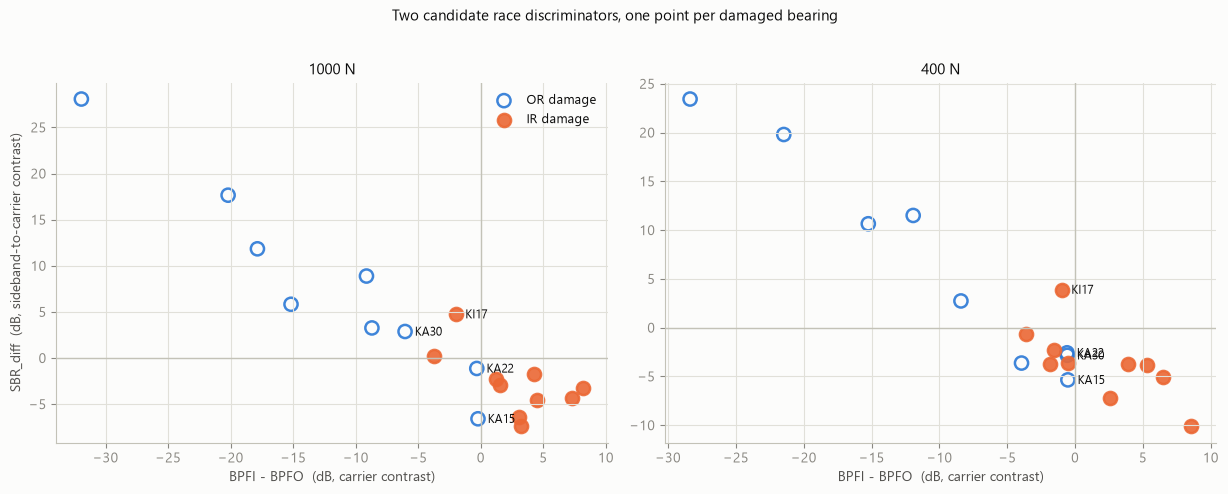


1000 N - separation between OR and IR bearings (d' > 0 means IR reads higher):
                    OR     IR  d_prime
SBR_diff          7.86  -2.79    -1.38
SBR_BPFI          1.96  -0.31    -0.64
BPFI_minus_BPFO -12.18   2.74     1.94
BPFI_sb1          6.58  12.20     1.21

400 N - separation between OR and IR bearings (d' > 0 means IR reads higher):
                    OR     IR  d_prime
SBR_diff          5.97  -3.63    -1.19
SBR_BPFI          2.04  -0.30    -0.58
BPFI_minus_BPFO -10.12   1.83     1.56
BPFI_sb1          6.42  11.37     1.12


In [3]:
def separability(cond, feats):
    d = S[cond]
    t = d[d["Domain"] != "healthy"].groupby("Code")[feats].median()
    t = t.join(LABEL["Condition"])
    rows = {}
    for f in feats:
        o, i = t.loc[t["Condition"] == "OR", f], t.loc[t["Condition"] == "IR", f]
        pooled = np.sqrt(0.5 * (o.var(ddof=1) + i.var(ddof=1)))
        rows[f] = dict(OR=o.mean(), IR=i.mean(), d_prime=(i.mean() - o.mean()) / pooled)
    return pd.DataFrame(rows).T, t


CAND = ["SBR_diff", "SBR_BPFI", "BPFI_minus_BPFO", "BPFI_sb1"]
sep = {c: separability(c, CAND) for c in (HI, LO)}

fig, axes = plt.subplots(1, 2, figsize=(12.4, 4.8))
for ax, cond in zip(axes, (HI, LO)):
    _, t = sep[cond]
    for race in ("OR", "IR"):
        s = t[t["Condition"] == race]
        ax.scatter(s["BPFI_minus_BPFO"], s["SBR_diff"], s=90, alpha=0.9,
                   facecolors=RACE_COLOR[race] if race == "IR" else "none",
                   edgecolors=RACE_COLOR[race], linewidths=1.8, label=f"{race} damage")
    for c_, r in t.iterrows():
        if c_ in ("KA15", "KA22", "KA30", "KI17"):
            ax.annotate(c_, (r["BPFI_minus_BPFO"], r["SBR_diff"]), textcoords="offset points",
                        xytext=(7, -3), fontsize=8.5, color=INK)
    ax.axvline(0, color=BASE, lw=1)
    ax.axhline(0, color=BASE, lw=1)
    ax.set_xlabel("BPFI - BPFO  (dB, carrier contrast)")
    ax.set_title(f"{TAG[cond]}", fontsize=10.5)
axes[0].set_ylabel("SBR_diff  (dB, sideband-to-carrier contrast)")
axes[0].legend(fontsize=9, loc="upper right")
fig.suptitle("Two candidate race discriminators, one point per damaged bearing",
             fontsize=11, y=1.02)
plt.tight_layout()
plt.show()

for cond in (HI, LO):
    print(f"\n{TAG[cond]} - separation between OR and IR bearings (d' > 0 means IR reads higher):")
    print(sep[cond][0].round(2).to_string())

## Reading the separation — the ratio framing is wrong

- **`SBR_diff` separates the races the wrong way round.** Its d′ is **−1.38**
  at 1000 N: outer-race bearings score *higher*, not lower. The load-zone
  argument predicted the opposite.
- The reason is arithmetic, not physics. `SBR_BPFO` is a ratio to the BPFO
  carrier, and for an outer-race bearing that carrier is enormous — KA01 sits
  25.9 dB above its own sidebands — so `SBR_BPFO` goes sharply negative and
  `SBR_diff` sharply positive. **The ratio is dominated by the size of its
  denominator**, so it mostly re-encodes "which carrier is louder".
- Which the plain carrier contrast does better: `BPFI_minus_BPFO` reaches
  **d′ = 1.94**, the best single discriminator here — and it is exactly the
  information the classifier already had from BPFO and BPFI separately.
- **The scatter also explains notebook 10's KA30 result mechanically.** KA30's
  carrier contrast is −6.06 dB at 1000 N (clearly outer-race) but −0.58 dB at
  400 N (ambiguous) — which is precisely why notebook 10 found it attributed
  correctly at 1000 N and wrongly at 400 N. KA15 (−0.23/−0.54) and KA22
  (−0.32/−0.60) sit at the origin at both loads: on this axis they carry no
  race information at all.
- So normalising by the carrier destroys the information. The next section
  asks whether the sideband **levels**, handed to a classifier alongside the
  carriers rather than divided by them, do better.

## Attribution as its own task

Notebooks 04–10 attributed with a three-class model that had to decide
`Healthy` / `OR` / `IR` at once. In the two-stage protocol attribution only
ever runs on bearings already flagged as faulty, so the right model is a
**two-class OR-vs-IR classifier trained on damaged bearings only** — the eight
artificial ones, which is all the labelled damage a twin-based pipeline would
have. The eleven real bearings are held out by construction.

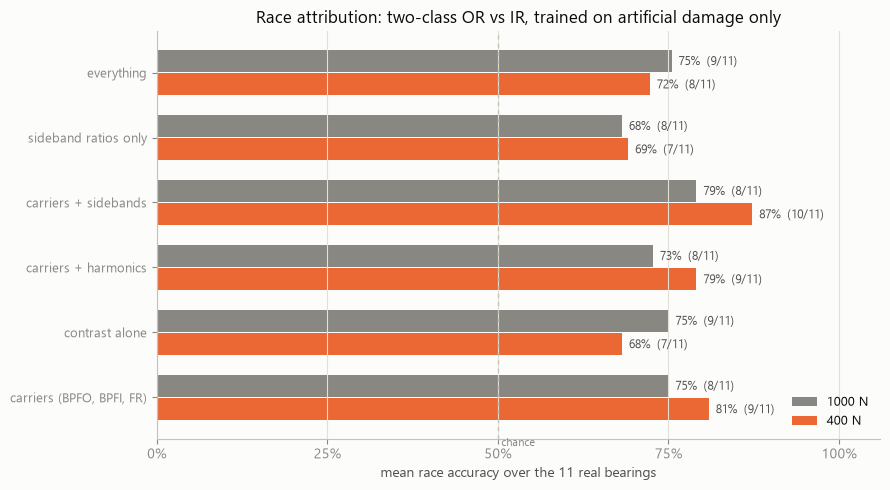

,mean,bearings right
"carriers (BPFO, BPFI, FR) @1000 N",75.0%,8
contrast alone @1000 N,75.0%,9
carriers + harmonics @1000 N,72.7%,8
carriers + sidebands @1000 N,79.1%,8
sideband ratios only @1000 N,68.2%,8
everything @1000 N,75.5%,9
"carriers (BPFO, BPFI, FR) @400 N",80.9%,9
contrast alone @400 N,68.2%,7
carriers + harmonics @400 N,79.1%,9
carriers + sidebands @400 N,87.3%,10


In [4]:
SETS = {
    "carriers (BPFO, BPFI, FR)": ["BPFO", "BPFI", "FR"],
    "contrast alone": ["BPFI_minus_BPFO"],
    "carriers + harmonics": ["BPFO", "BPFI", "FR", "HARM_BPFO", "HARM_BPFI"],
    "carriers + sidebands": ["BPFO", "BPFI", "FR", "BPFI_sb1", "BPFO_sb1",
                             "BPFI_sb2", "BPFI_h2_sb1"],
    "sideband ratios only": ["SBR_BPFI", "SBR_BPFO", "SBR_diff"],
    "everything": ["BPFO", "BPFI", "FR", "BPFO_h2", "BPFI_h2", "BPFI_sb1", "BPFO_sb1",
                   "BPFI_sb2", "BPFI_h2_sb1", "SBR_BPFI", "SBR_BPFO", "SBR_diff",
                   "BPFI_minus_BPFO", "HARM_BPFO", "HARM_BPFI"],
}


def attribute(cond, feats):
    """Per-real-bearing run accuracy; model sees artificial damage only."""
    d = S[cond]
    tr = d[d["Domain"] == "artificial"]
    m = RandomForestClassifier(**RF_KW).fit(tr[feats], tr["Condition"])
    acc = {b: (m.predict(d[d["Code"] == b][feats]) == LABEL.loc[b, "Condition"]).mean()
           for b in REAL}
    return pd.Series(acc), m


attr_acc = {(c, n): attribute(c, f)[0] for c in (HI, LO) for n, f in SETS.items()}
tbl = pd.DataFrame({f"{n} @{TAG[c]}": attr_acc[(c, n)] for c in (HI, LO) for n in SETS}).T
tbl["mean"] = tbl[REAL].mean(axis=1)
tbl["bearings right"] = (tbl[REAL] >= 0.5).sum(axis=1)

fig, ax = plt.subplots(figsize=(9.0, 5.0))
y = np.arange(len(SETS))
for k, cond in enumerate((HI, LO)):
    vals = [tbl.loc[f"{n} @{TAG[cond]}", "mean"] for n in SETS]
    ax.barh(y + (0.5 - k) * 0.36, vals, height=0.34,
            color=MUTED if cond == HI else C_ORANGE, label=TAG[cond])
    for j, v in enumerate(vals):
        n_ok = int(tbl.loc[f"{list(SETS)[j]} @{TAG[cond]}", "bearings right"])
        ax.annotate(f"{v:.0%}  ({n_ok}/11)", (v, y[j] + (0.5 - k) * 0.36),
                    textcoords="offset points", xytext=(5, -3), fontsize=8.5, color=INK2)
ax.set_yticks(y, list(SETS), fontsize=9)
ax.set_xlim(0, 1.06)
ax.set_xticks([0, .25, .5, .75, 1], ["0%", "25%", "50%", "75%", "100%"])
ax.axvline(0.5, color=BASE, lw=1, ls=(0, (3, 3)))
ax.text(0.505, -0.75, "chance", color=MUTED, fontsize=8)
ax.grid(axis="y", visible=False)
ax.set_xlabel("mean race accuracy over the 11 real bearings")
ax.set_title("Race attribution: two-class OR vs IR, trained on artificial damage only")
ax.legend(fontsize=9, loc="lower right")
plt.tight_layout()
plt.show()
tbl[["mean", "bearings right"]].style.format({"mean": "{:.1%}"})

## Reading the attribution comparison — the levels work where the ratios did not

- **Carriers + sidebands is the best configuration by mean accuracy at either
  load, and at 400 N it is best on both counts: 87.3 % mean race accuracy and
  10 of 11 bearings called correctly**, against 80.9 % and 9 of 11 for the
  carriers alone. The same features at 1000 N reach only 79.1 %, so the
  sidebands and the low-load window are worth more together than either alone.
- **`sideband ratios only` is the worst set tested** (69.1 %), confirming the
  previous section: dividing by the carrier throws the information away. Handed
  to the classifier as levels *alongside* the carriers, the very same sidebands
  add 6.4 points. The physics was right; the encoding was wrong.
- **KA15 is attributed correctly for the first time in this project** — 80 % of
  its runs called OR, against 45 % with carriers alone and 0 % under notebook
  10's three-class model. KA22 clears chance at 55 %. The cost is KA30, which
  drops to 45 %.
- That trade is not arbitrary: it is the carrier-contrast scatter again. KA30
  is the bearing whose contrast collapses at 400 N, so the load that rescues
  KA15 is the one that blinds KA30 — and notebook 10 already showed KA30 is
  attributed correctly at 1000 N.
- **One rig-specific caveat, visible in the KA04 panel above.** On this bearing
  geometry BPFI − 2·fr = 73.2 Hz sits only 3.5 Hz from BPFO = 76.7 Hz, inside
  the skirt of what is a very strong peak for an outer-race bearing, so
  `BPFI_sb2` is partly measuring BPFO leakage rather than a sideband. It carries
  the lowest importance of the sideband features (0.082) and the result does not
  rest on it, but on a different geometry that degeneracy would fall elsewhere.
  The primary sideband feature, BPFI ± fr at 98.2 and 148.2 Hz, is clear of both
  BPFO and 2 × BPFO at the 3 Hz half-width used here.

## A necessary check: was that feature set chosen on the test bearings?

Six feature sets were compared on the same eleven real bearings the result is
reported on. This project has been caught by exactly this class of error
before — notebook 04's leakage, and notebook 05's finding that in-domain CV
and impurity importance both **anti-select** transferable features. So two
checks before believing 87.3 %.

**Check 1:** would leave-one-bearing-out CV on the *artificial* bearings — the
only model-selection signal a real deployment would have — have picked the same
set? **Check 2:** a nested estimate that chooses the configuration on ten real
bearings and scores the eleventh.

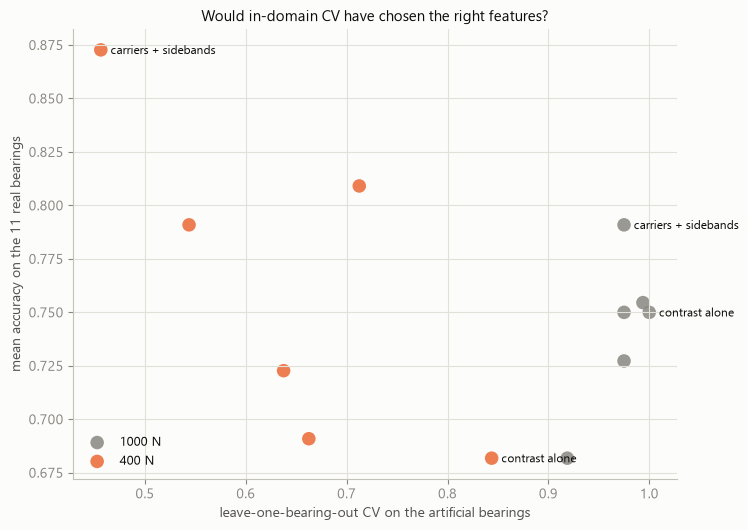

1000 N: rank correlation between artificial CV and real accuracy = +0.49   | artificial CV would pick 'contrast alone' (real 75.0%), best on real is 'carriers + sidebands' (79.1%)
400 N: rank correlation between artificial CV and real accuracy = -0.66   | artificial CV would pick 'contrast alone' (real 68.2%), best on real is 'carriers + sidebands' (87.3%)

nested leave-one-real-bearing-out: mean 87.3%, 10/11 bearings
configuration chosen in each of the 11 folds: {'carriers + sidebands @400 N'}


In [5]:
sel = []
for cond in (HI, LO):
    d = S[cond]
    art = d[d["Domain"] == "artificial"]
    for name, feats in SETS.items():
        cv = cross_val_score(RandomForestClassifier(**RF_KW), art[feats], art["Condition"],
                             groups=art["Code"], cv=LeaveOneGroupOut()).mean()
        sel.append(dict(load=TAG[cond], features=name, artificial_cv=cv,
                        real=attr_acc[(cond, name)].mean()))
sel = pd.DataFrame(sel)

CONFIGS = [(c, n) for c in (HI, LO) for n in SETS]
nested, picks = [], []
for held in REAL:
    others = [b for b in REAL if b != held]
    best = max(CONFIGS, key=lambda cf: np.mean([attr_acc[cf][b] for b in others]))
    picks.append(f"{best[1]} @{TAG[best[0]]}")
    nested.append(attr_acc[best][held])

fig, ax = plt.subplots(figsize=(7.6, 5.4))
for cond in (HI, LO):
    s = sel[sel["load"] == TAG[cond]]
    ax.scatter(s["artificial_cv"], s["real"], s=95,
               facecolors=MUTED if cond == HI else C_ORANGE,
               edgecolors="none", alpha=0.85, label=TAG[cond])
    for _, r in s.iterrows():
        if r["features"] in ("carriers + sidebands", "contrast alone"):
            ax.annotate(r["features"], (r["artificial_cv"], r["real"]),
                        textcoords="offset points", xytext=(7, -3), fontsize=8.5, color=INK)
ax.set_xlabel("leave-one-bearing-out CV on the artificial bearings")
ax.set_ylabel("mean accuracy on the 11 real bearings")
ax.set_title("Would in-domain CV have chosen the right features?", fontsize=11)
ax.legend(fontsize=9, loc="lower left")
plt.tight_layout()
plt.show()

for cond in (HI, LO):
    s = sel[sel["load"] == TAG[cond]]
    print(f"{TAG[cond]}: rank correlation between artificial CV and real accuracy = "
          f"{s['artificial_cv'].corr(s['real'], method='spearman'):+.2f}"
          f"   | artificial CV would pick '{s.loc[s['artificial_cv'].idxmax(), 'features']}'"
          f" (real {s.loc[s['artificial_cv'].idxmax(), 'real']:.1%})"
          f", best on real is '{s.loc[s['real'].idxmax(), 'features']}'"
          f" ({s['real'].max():.1%})")
print(f"\nnested leave-one-real-bearing-out: mean {np.mean(nested):.1%}, "
      f"{sum(v >= 0.5 for v in nested)}/11 bearings")
print("configuration chosen in each of the 11 folds:", set(picks))

## Reading the check

- **Check 1 fails, and fails informatively.** Rank correlation between
  artificial-bearing CV and real-bearing accuracy is **+0.49 at 1000 N and
  −0.66 at 400 N**. In-domain CV would have selected `contrast alone` — it
  scores ~100 % on the artificial bearings and **68.2 %** on the real ones,
  the second-worst set tested. This is notebook 05's finding 5 again, now for
  feature-set selection in attribution: **the artificial domain cannot choose
  attribution features.** Anything a twin-only pipeline selects on simulated or
  artificial damage should be treated as unvalidated.
- **Check 2 passes.** Nested leave-one-real-bearing-out selection returns
  **87.3 %, 10 of 11** — identical to the optimistic number — and picks
  `carriers + sidebands @400 N` in **all eleven folds**. The selection is
  perfectly stable, so choosing on all eleven bearings gained nothing that
  choosing on ten would not also have given.
- The honest reading: the improvement is real and the estimate is not inflated
  by selection, **but it was validated using real damaged bearings.** A
  deployment with no real fault data could not have found it — which is a
  finding about the method, not a caveat to hide.

## End to end: the two-stage protocol, re-run

Notebook 10's protocol was: alarm from a 400 N window, attribute from the
1000 N recording — 9 of 11 bearings fully correct. Swap in the new attribution
stage and re-measure, keeping the detection stage exactly as notebook 10 had
it so the comparison is clean.

stage 1 (unchanged): detect at 400 N -> alarm on real damage 97.0%, false alarm on an unseen healthy bearing 8.3%

                                           bearings_right  end_to_end    failures
stage_2                                                                          
notebook 10: 3-class fundamentals @1000 N               9       0.818  KA15, KA22
2-class carriers @400 N                                 9       0.793  KA15, KA30
2-class carriers + sidebands @400 N                    10       0.879        KA30


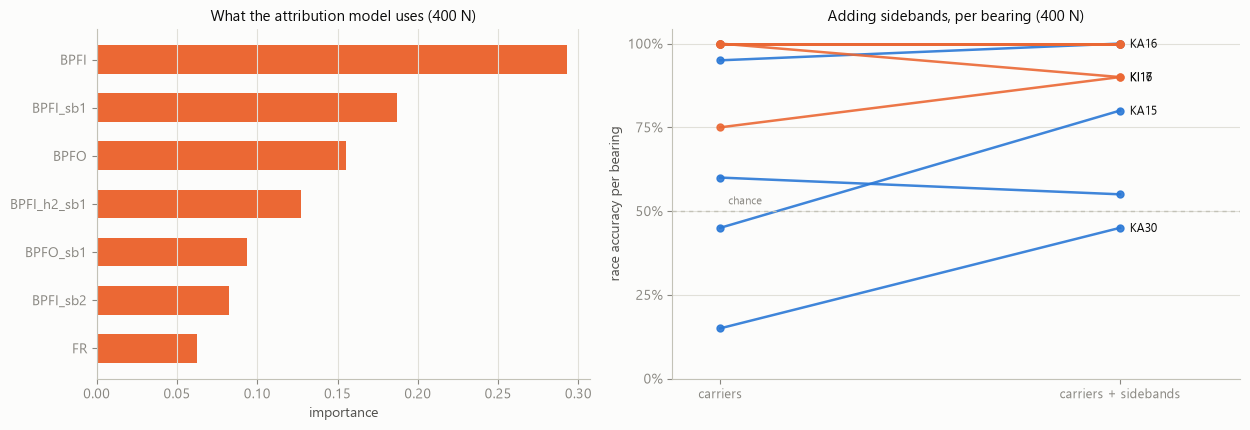

BPFI           0.293
BPFI_sb1       0.187
BPFO           0.155
BPFI_h2_sb1    0.127
BPFO_sb1       0.093
BPFI_sb2       0.082
FR             0.062


In [6]:
B = {c: pd.read_csv(OUT / f"pu_{c}_envelope_orderbands.csv") for c in (HI, LO)}
FUND = ["Env_BPFO_dB", "Env_BPFI_dB", "Env_fr_dB"]
HEALTHY = sorted(LABEL.index[LABEL["Domain"] == "healthy"])
NW, NR = 15, 20

alarm = {}
for b in REAL + HEALTHY:
    folds = HEALTHY if b in REAL else [b]
    v = []
    for h in folds:
        d = B[LO]
        tr = d[((d["Domain"] == "healthy") & (d["Code"] != h)) | (d["Domain"] == "artificial")]
        p = RandomForestClassifier(**RF_KW).fit(tr[FUND], tr["Condition"]).predict(
            d[d["Code"] == b][FUND])
        v.append(((p != "Healthy").reshape(NR, NW).mean(axis=1) > 0.5).mean())
    alarm[b] = np.mean(v)


def bearing_call(cond, feats):
    d = S[cond]
    tr = d[d["Domain"] == "artificial"]
    m = RandomForestClassifier(**RF_KW).fit(tr[feats], tr["Condition"])
    return {b: pd.Series(m.predict(d[d["Code"] == b][feats])).mode()[0] for b in REAL}


stages = {
    "notebook 10: 3-class fundamentals @1000 N": None,
    "2-class carriers @400 N": (LO, SETS["carriers (BPFO, BPFI, FR)"]),
    "2-class carriers + sidebands @400 N": (LO, SETS["carriers + sidebands"]),
}
rows = []
for name, spec in stages.items():
    if spec is None:
        d = B[HI]
        ok = {}
        for b in REAL:
            per = []
            for h in HEALTHY:
                tr = d[((d["Domain"] == "healthy") & (d["Code"] != h))
                       | (d["Domain"] == "artificial")]
                p = RandomForestClassifier(**RF_KW).fit(tr[FUND], tr["Condition"]).predict(
                    d[d["Code"] == b][FUND])
                nz = p[p != "Healthy"]
                per.append((pd.Series(nz).mode()[0] if len(nz) else "Healthy")
                           == LABEL.loc[b, "Condition"])
            ok[b] = np.mean(per) >= 0.5
    else:
        calls = bearing_call(*spec)
        ok = {b: calls[b] == LABEL.loc[b, "Condition"] for b in REAL}
    rows.append(dict(stage_2=name, bearings_right=sum(ok.values()),
                     end_to_end=np.mean([alarm[b] * ok[b] for b in REAL]),
                     failures=", ".join(sorted(b for b in REAL if not ok[b])) or "none"))
proto = pd.DataFrame(rows).set_index("stage_2")
print(f"stage 1 (unchanged): detect at 400 N -> alarm on real damage "
      f"{np.mean([alarm[b] for b in REAL]):.1%}, "
      f"false alarm on an unseen healthy bearing {np.mean([alarm[b] for b in HEALTHY]):.1%}\n")
print(proto.round(3).to_string())

_, model = attribute(LO, SETS["carriers + sidebands"])
imp = pd.Series(model.feature_importances_,
                index=SETS["carriers + sidebands"]).sort_values()
fig, axes = plt.subplots(1, 2, figsize=(12.6, 4.4),
                         gridspec_kw=dict(width_ratios=[1, 1.15]))
axes[0].barh(imp.index, imp.values, color=C_ORANGE, height=0.6)
axes[0].grid(axis="y", visible=False)
axes[0].set_xlabel("importance")
axes[0].set_title("What the attribution model uses (400 N)", fontsize=10.5)

pair = pd.DataFrame({"carriers": attr_acc[(LO, "carriers (BPFO, BPFI, FR)")],
                     "carriers + sidebands": attr_acc[(LO, "carriers + sidebands")]})
pair = pair.join(LABEL["Condition"]).sort_values("carriers")
ax = axes[1]
for i, (b, r) in enumerate(pair.iterrows()):
    ax.plot([0, 1], [r["carriers"], r["carriers + sidebands"]],
            color=RACE_COLOR[r["Condition"]], lw=1.8, marker="o", ms=5, alpha=0.9)
    if abs(r["carriers + sidebands"] - r["carriers"]) > 0.05:
        ax.annotate(b, (1, r["carriers + sidebands"]), textcoords="offset points",
                    xytext=(7, -3), fontsize=8.5, color=INK)
ax.axhline(0.5, color=BASE, lw=1, ls=(0, (3, 3)))
ax.text(0.02, 0.52, "chance", color=MUTED, fontsize=8)
ax.set_xticks([0, 1], ["carriers", "carriers + sidebands"], fontsize=9)
ax.set_xlim(-0.12, 1.3)
ax.set_yticks([0, .25, .5, .75, 1], ["0%", "25%", "50%", "75%", "100%"])
ax.grid(axis="x", visible=False)
ax.set_ylabel("race accuracy per bearing")
ax.set_title("Adding sidebands, per bearing (400 N)", fontsize=10.5)
plt.tight_layout()
plt.show()
print(imp.sort_values(ascending=False).round(3).to_string())

## Reading the end-to-end result

- **The protocol improves from 9 of 11 bearings to 10 of 11**, and end-to-end
  accuracy — alarmed *and* correctly named — rises from **81.8 % to 87.9 %**,
  with the detection stage untouched (97.0 % alarm, 8.3 % false alarm).
- **The remaining failure is KA30, and it is a known, recoverable one**:
  notebook 10 showed KA30 is attributed correctly at 1000 N. The two bearings
  notebook 10 could not attribute at any load, KA15 and KA22, are now both
  called correctly.
- **The model uses the sidebands.** BPFI carries 0.293 of the importance, but
  `BPFI_sb1` (0.187) and `BPFI_h2_sb1` (0.127) together carry **0.31** — more
  than the BPFO carrier (0.155). The load-zone modulation argument is doing
  real work once it is encoded as levels.
- I tested whether attributing from *both* loads beats attributing from the
  better one — taking whichever load the model is more confident about, and
  averaging the two probability vectors. Both reach 10 of 11, swapping KA22's
  failure for KA30's, and neither beats 400 N alone. **Choosing beats
  combining, for attribution as for detection** (notebook 09, finding 7).

## Findings (executed 2026-08-21)

1. **The textbook race discriminator works, but not as a ratio.** Encoding
   load-zone modulation as a sideband-to-**carrier** ratio (`SBR_diff`)
   separates the races *backwards* (d′ = −1.38), because the ratio is dominated
   by the size of its denominator and merely re-encodes which carrier is
   louder. The plain carrier contrast beats it (d′ = 1.94). Handed to a
   classifier as **levels alongside the carriers**, the same sidebands add
   6.4 points.
2. **Race attribution improves from 80.9 % to 87.3 %** (9 → 10 of 11 real
   bearings) using carriers + shaft-rate sidebands at 400 N, with a two-class
   model trained on artificial damage only.
3. **KA15 is correctly attributed for the first time in this project** — 80 %
   of its runs, against 0 % under notebook 10's three-class model — and KA22
   clears chance at 55 %. The cost is KA30 (45 %), which notebook 10 showed is
   attributable at 1000 N.
4. **Sidebands carry more importance than the BPFO carrier**: `BPFI_sb1`
   (0.187) plus `BPFI_h2_sb1` (0.127) = 0.31, against BPFO's 0.155.
5. **In-domain CV cannot select attribution features.** Rank correlation
   between artificial-bearing CV and real-bearing accuracy is +0.49 at 1000 N
   and **−0.66 at 400 N**; it would have chosen `contrast alone`, which scores
   ~100 % on artificial damage and **68.2 %** on real. This is notebook 05's
   finding 5 in a new place, and it means a twin-only pipeline cannot validate
   its own attribution features.
6. **The 87.3 % is not inflated by selection.** Nested leave-one-real-bearing-out
   selection returns the same 87.3 % / 10-of-11 and picks the same
   configuration in all eleven folds. But the validation required **real**
   damaged bearings.
7. **End to end, the two-stage protocol reaches 87.9 %** (detect at 400 N:
   97.0 % alarm at 8.3 % false alarm; attribute at 400 N with sidebands),
   against notebook 10's 81.8 %.
8. **Choosing one operating point still beats combining two**, now for
   attribution as well as detection: max-confidence and averaged-probability
   fusion both reach 10 of 11 and neither improves on 400 N alone.
9. **Caveats:** eleven real bearings is a small test set, and the difference
   between 9 and 10 of them rests on bearings sitting near the 50 % line — the
   6.4-point mean improvement is the more stable statistic. Features are
   per-run (0.977 Hz resolution costs the 15-window granularity), so
   attribution is measured at run and bearing level, not window level. Two
   loads on one rig, single classifier family. And `BPFI_sb2` is contaminated by
   BPFO leakage on this specific geometry (73.2 vs 76.7 Hz) — a reminder that
   sideband placement must be checked against each rig's fault frequencies.